# COGS 109 Project Checkpoint 2: Logistic Regression, Model Selection, and Regularization

**Due Monday, November 16 at 11:59pm PT.** This notebook walks you through every step of Checkpoint 2, in the same order as the guidelines.

**Before you start**

- Make your own copy: **File → Save a copy in Drive**.
- Rename it with your name, for example `CP2_Ana_Lopez.ipynb`, and put it in your group's shared Google Drive folder. That folder is what your group submits.
- Edit the cells marked ✏️. Every other cell runs as is.

**What's in it**

| Step | Who | What you do |
| --- | --- | --- |
| 1. Turn your outcome into a binary outcome | Group (same in every copy) | Load your Checkpoint 1 data, choose a threshold, check the class balance, list your candidate predictors |
| 2. Test set and validation folds | Group (same in every copy) | Reuse your Checkpoint 1 train/test split and make k folds for cross-validation |
| 3. Choose your predictors with cross-validation | You | Run your selection method (a different one for each member) and plot CV error, AIC, and BIC |
| 4. Compare and interpret your selected model | You | Report AIC, BIC, and CV error rate, write the model in math, interpret odds ratios |
| 5. Test your final model | You | Test accuracy, confusion matrix, precision, recall, and the ROC curve with its AUC |
| 6. Compare models | One member | Put everyone's results in one table |

**About the example data.** So you can see what every step produces, this notebook runs on `Hitters`: salaries and batting statistics for 263 Major League Baseball players (1986–87), from the ISLP textbook. The binary outcome is whether a player earned **more than $500,000**. Replace it with your group's dataset in Step 1.

**Remember:** the point of the project is not to maximize your accuracy, but to follow the **entire predictive modeling workflow correctly**. Don't worry if your accuracy or other metrics are not very good.

**Before you submit**, choose **Runtime → Restart and run all**. Your notebook must run from top to bottom without errors, and its figures must match your slides.

In [1]:
# Setup (no need to edit)
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display, Math, Markdown

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

---
# Step 1. Turn your outcome into a binary outcome (group)

Agree on Steps 1 and 2 as a group, then copy the **same** cells into every member's notebook. Logistic regression predicts a yes/no outcome, so your group turns its Checkpoint 1 outcome into two classes.

### 1a. ✏️ Load your Checkpoint 1 data

Use the same file, outcome, random seed, and test fraction as in Checkpoint 1.

- `OUTCOME`: your **continuous** Checkpoint 1 outcome. You turn it into a binary outcome in 1c.
- `SEED` and `TEST_FRACTION`: copy them from your Checkpoint 1 notebook, so your test set is the same one.

In [2]:
# ✏️ EDIT: your group's dataset, exactly as in Checkpoint 1
DATA_PATH = "../../data/online_shoppers_intention.csv"
OUTCOME = "ProductRelated_Duration"
SEED = 109
TEST_FRACTION = 0.2

df = pd.read_csv(DATA_PATH)
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### 1b. ✏️ Clean the data and leave out text and date/time columns

- Use the same cleaning steps as Checkpoint 1, so you keep the same rows.
- List every **text** column (free-text answers, names, IDs) and every **date or time** column in `DROP_COLUMNS`. These are not candidate predictors in this class.
- If a column is a category coded as numbers, convert it with `.astype(str)` so it's treated as qualitative.

The table below flags columns that look like text or dates. Check every column yourself too.

In [3]:
# ✏️ EDIT: cleaning steps (same as Checkpoint 1) and the text/date columns to leave out
n_before = len(df)
df = df.dropna()

# df["Region"] = df["Region"].astype(str)       # example: treat a number-coded category as qualitative
for c in ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend", "Revenue"]:
    df[c] = df[c].astype(str)

DROP_COLUMNS = []

df = df.drop(columns=DROP_COLUMNS)
print(f"Dropped {n_before - len(df)} rows with missing values; {len(df)} rows remain.")


def _looks_like(col):
    s = df[col]
    if pd.api.types.is_datetime64_any_dtype(s) or any(w in col.lower() for w in ("date", "time", "year_month", "timestamp")):
        return "date/time? consider dropping"
    if not pd.api.types.is_numeric_dtype(s) and s.nunique() > 50:
        return "text or ID? consider dropping"
    return ""


overview = pd.DataFrame({
    "type": ["quantitative" if pd.api.types.is_numeric_dtype(df[c]) else "qualitative" for c in df.columns],
    "distinct values": df.nunique(),
    "example": df.iloc[0],
    "flag": [_looks_like(c) for c in df.columns],
})
overview

Dropped 0 rows with missing values; 12330 rows remain.


,type,distinct values,example,flag
Administrative,quantitative,27,0,
Administrative_Duration,quantitative,3335,0.0,
Informational,quantitative,17,0,
Informational_Duration,quantitative,1258,0.0,
ProductRelated,quantitative,311,1,
ProductRelated_Duration,quantitative,9551,0.0,
BounceRates,quantitative,1872,0.2,
ExitRates,quantitative,4777,0.2,
PageValues,quantitative,2704,0.0,
SpecialDay,quantitative,6,0.0,


In [4]:
# Remove Outliers by 1.5 x IQR Rule.
n_before = len(df)
y = df["ProductRelated_Duration"]
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
df = df[(y >= q1 - 1.5 * iqr) & (y <= q3 + 1.5 * iqr)]

print(f"Dropped {n_before - len(df)} rows that were considered outliers; {len(df)} rows remain.")

Dropped 961 rows that were considered outliers; 11369 rows remain.


### 1c. ✏️ Choose your threshold (Slide 1)

Your new outcome is **1** when the Checkpoint 1 outcome is **above** the threshold, and **0** when it is at or below it.

- Choose a threshold that means something to your audience, such as a passing grade, a health cutoff, or a price point.
- If there is no natural cutoff, set `THRESHOLD = "median"`. The notebook then uses the median of the **training set**, so the classes split roughly 50/50.
- `CLASS_1` and `CLASS_0` are short names for the two classes, used in plots and sentences.

In [5]:
# ✏️ EDIT: your threshold and the names of your two classes
THRESHOLD = df["ProductRelated_Duration"].median() # a number, or "median" (here, $500K)
Y_NAME = "EngagedUser"            # name of the new 0/1 outcome
CLASS_1 = "spent more than 516.479 seconds (8.61 minutes) browsing product pages"
CLASS_0 = "spent 516.479 seconds (8.61 minutes) or less browsing product pages"

# The training rows are the same ones Step 2 uses (same seed and test fraction)
_train_rows, _ = train_test_split(df.index, test_size=TEST_FRACTION, random_state=SEED)
cutoff = df.loc[_train_rows, OUTCOME].median() if THRESHOLD == "median" else THRESHOLD

df[Y_NAME] = (df[OUTCOME] > cutoff).astype(int)
print(f"{Y_NAME} = 1 if {OUTCOME} > {cutoff:g}   ({CLASS_1})")
print(f"{Y_NAME} = 0 if {OUTCOME} <= {cutoff:g}  ({CLASS_0})")

EngagedUser = 1 if ProductRelated_Duration > 516.479   (spent more than 516.479 seconds (8.61 minutes) browsing product pages)
EngagedUser = 0 if ProductRelated_Duration <= 516.479  (spent 516.479 seconds (8.61 minutes) or less browsing product pages)


### 1d. Check the class balance (Slide 1)

What proportion of the **training set** is 1? Aim for at least 20% of rows in each class. If one class is very rare, be prepared to address class imbalance using the methods from class.

Training set: 50.1% are 1 (spent more than 516.479 seconds (8.61 minutes) browsing product pages), 49.9% are 0 (spent 516.479 seconds (8.61 minutes) or less browsing product pages)
✅ At least 20% of training rows in each class


C:\Users\jdoan\AppData\Local\Temp\ipykernel_35280\3664870640.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


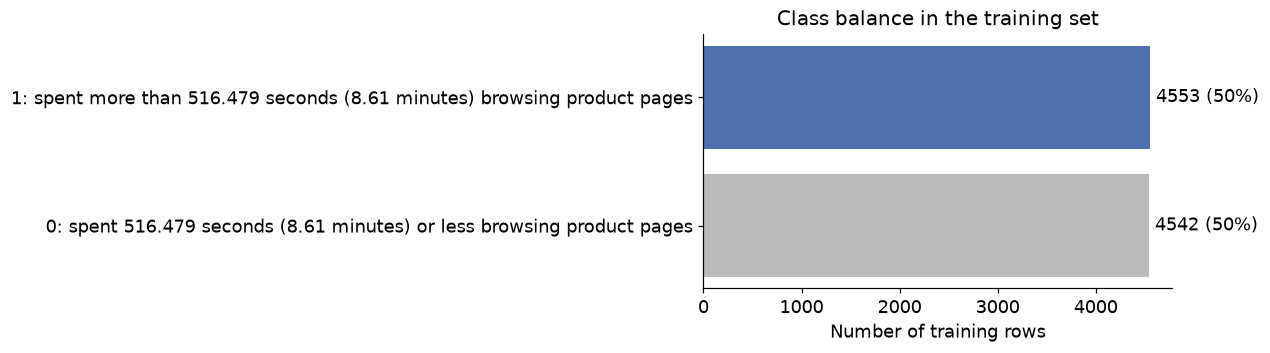

In [6]:
share_1 = df.loc[_train_rows, Y_NAME].mean()
print(f"Training set: {share_1:.1%} are 1 ({CLASS_1}), {1 - share_1:.1%} are 0 ({CLASS_0})")
print(("✅ " if 0.2 <= share_1 <= 0.8 else "⚠️ ") + "At least 20% of training rows in each class")

fig, ax = plt.subplots(figsize=(5.5, 3))
counts = df.loc[_train_rows, Y_NAME].value_counts().reindex([0, 1])
ax.barh([f"0: {CLASS_0}", f"1: {CLASS_1}"], counts.values, color=["#BBBBBB", "#4C72B0"])
for i, v in enumerate(counts.values):
    ax.text(v, i, f" {v} ({v / counts.sum():.0%})", va="center")
ax.set(xlabel="Number of training rows", title="Class balance in the training set")
plt.tight_layout()
plt.show()

✏️ **Write for Slide 1** (a few words each):

- **Your threshold, and why it means something to your audience:** median natural cutoff
- **Your modeling question for the binary outcome, in one sentence** (for example, *"What factors predict whether a player earns more than $500K?"*): what factors predict whether a sessions spends more than 8.61 minutes browsing product pages? 

### 1e. Your pool of candidate predictors (Slide 2)

Every member starts from the **same pool**: all the predictors in your dataset, leaving out text and date/time columns and the original continuous outcome. **Do NOT use the original continuous outcome as a predictor in your model.** It would give away the answer.

Each qualitative predictor becomes one dummy variable per category, minus the baseline. Count the dummies when you compare the number of predictors (p) with the number of training rows (n): it decides which selection methods you can use.

In [7]:
pool = [c for c in df.columns if c not in (OUTCOME, Y_NAME)]
quant = [c for c in pool if pd.api.types.is_numeric_dtype(df[c])]
qual = [c for c in pool if c not in quant]
n_dummies = sum(df[c].nunique() - 1 for c in qual)
p = len(quant) + n_dummies
n_train = len(_train_rows)

print(f"Candidate pool: {len(pool)} predictors ({len(quant)} quantitative, {len(qual)} qualitative)")
print("Quantitative:", quant)
print("Qualitative: ", {c: sorted(df[c].astype(str).unique().tolist()) for c in qual})
print(f"\np = {p} columns after dummy coding, n = {n_train} training rows")
if p >= n_train:
    print("⚠️ p is larger than n: backward stepwise won't work. Use forward stepwise, lasso, ridge, or elastic net.")
elif p > n_train / 10:
    print("⚠️ p is close to n: backward stepwise is unreliable. Lasso, ridge, and elastic net are the safest choices.")
else:
    print("✅ p is much smaller than n: every method in the table works.")

Candidate pool: 17 predictors (9 quantitative, 8 qualitative)
Quantitative: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Qualitative:  {'Month': ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep'], 'OperatingSystems': ['1', '2', '3', '4', '5', '6', '7', '8'], 'Browser': ['1', '10', '11', '12', '13', '2', '3', '4', '5', '6', '7', '8', '9'], 'Region': ['1', '2', '3', '4', '5', '6', '7', '8', '9'], 'TrafficType': ['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '3', '4', '5', '6', '7', '8', '9'], 'VisitorType': ['New_Visitor', 'Other', 'Returning_Visitor'], 'Weekend': ['False', 'True'], 'Revenue': ['False', 'True']}

p = 68 columns after dummy coding, n = 9095 training rows
✅ p is much smaller than n: every method in the table works.


### 1f. Explore the data (optional figures for your slides)

How does each predictor differ between the two classes? These help you understand what your selection methods find.

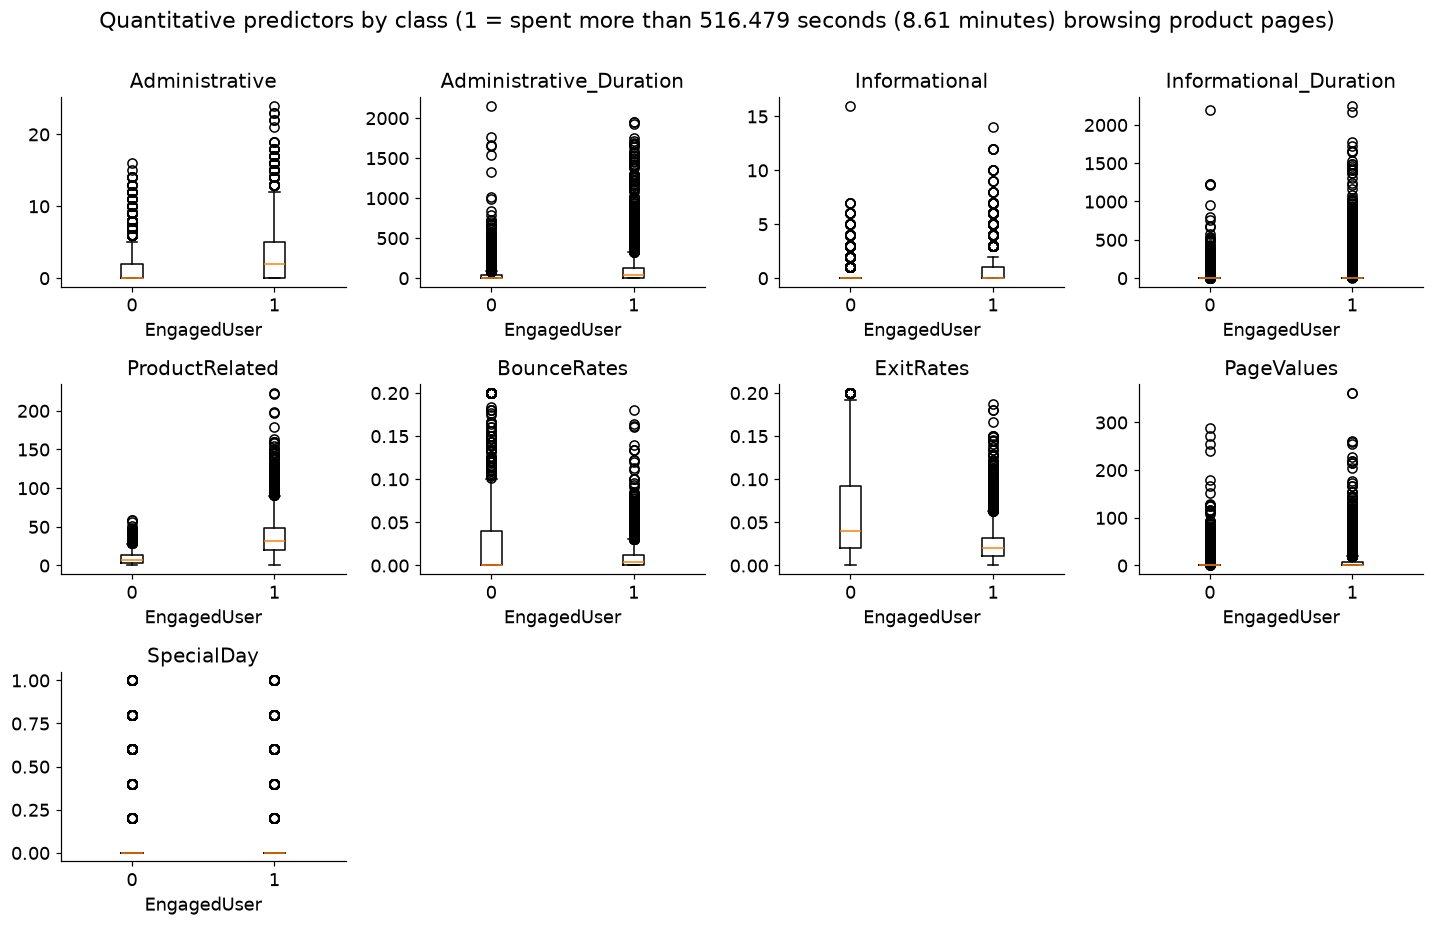

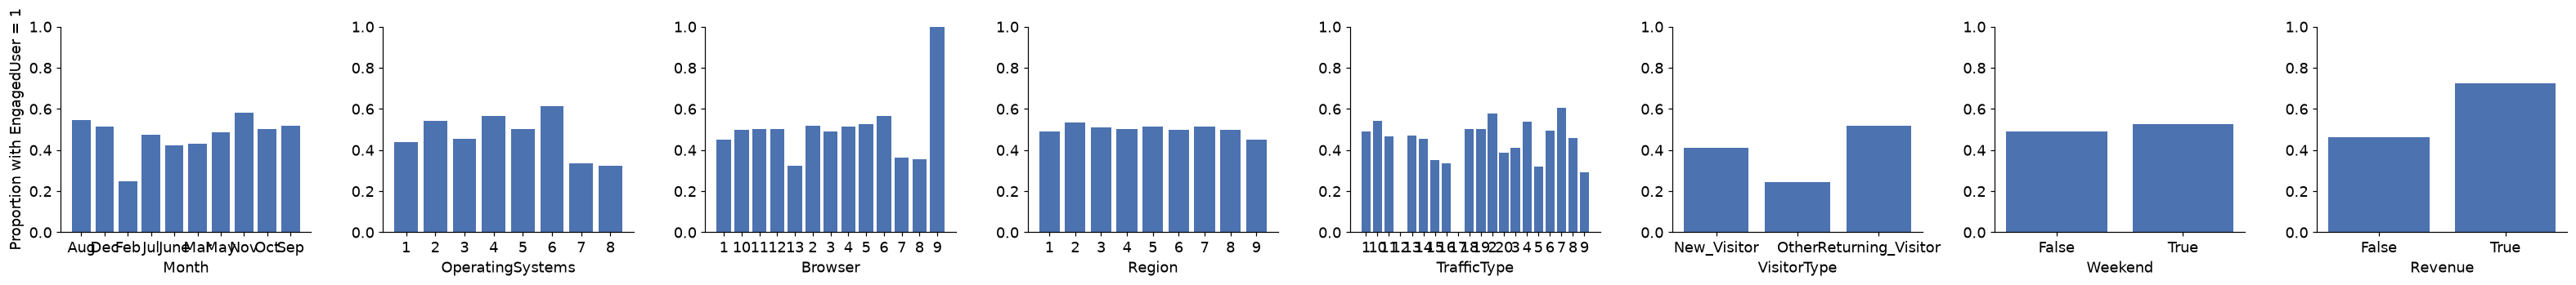

In [8]:
ncol = 4
nrow = int(np.ceil(len(quant) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 2.8 * nrow), squeeze=False)
for ax, col in zip(axes.flat, quant):
    ax.boxplot([df.loc[df[Y_NAME] == k, col] for k in (0, 1)])
    ax.set_xticks([1, 2], ["0", "1"])
    ax.set(title=col, xlabel=Y_NAME)
for ax in axes.flat[len(quant):]:
    ax.axis("off")
plt.suptitle(f"Quantitative predictors by class (1 = {CLASS_1})", y=1.0)
plt.tight_layout()
plt.show()

if qual:
    fig, axes = plt.subplots(1, len(qual), figsize=(3.6 * len(qual), 3.2), squeeze=False)
    for ax, col in zip(axes.flat, qual):
        share = df.groupby(df[col].astype(str))[Y_NAME].mean().sort_index()
        ax.bar(share.index, share.values, color="#4C72B0")
        ax.set(xlabel=col, ylim=(0, 1))
    axes[0, 0].set_ylabel(f"Proportion with {Y_NAME} = 1")
    plt.tight_layout()
    plt.show()

---
# Step 2. Keep your test set and set up your validation folds (group)

- **Use the same train/test split as Checkpoint 1** (the same proportions and random seed). The test set stays untouched until Step 5.
- **Split the training set into k folds** (k = 5 or 10), using one random seed for the whole group. In k-fold cross-validation, each fold takes a turn as the **validation set** while the model is fit on the other k − 1 folds. The average error across the k validation sets is your **CV error rate**: the proportion of validation cases your model misclassifies, using a 0.5 probability cutoff.
- Everyone uses the same folds. Otherwise your CV errors can't be compared. Compare both **fingerprints** with your teammates before anyone fits a model.

The folds are *stratified*: each fold keeps about the same share of 1s as the whole training set.

In [9]:
# ✏️ EDIT: agree on these as a group, then never change them
K = 5            # number of folds: 5 or 10
FOLD_SEED = 109  # random seed for the folds

train, test = train_test_split(df, test_size=TEST_FRACTION, random_state=SEED)
y_train, y_test = train[Y_NAME].to_numpy(), test[Y_NAME].to_numpy()
FOLDS = list(StratifiedKFold(n_splits=K, shuffle=True, random_state=FOLD_SEED).split(train, y_train))

fingerprint = hashlib.md5(str(sorted(test.index.tolist())).encode()).hexdigest()[:8]
fold_print = hashlib.md5(str([sorted(v.tolist()) for _, v in FOLDS]).encode()).hexdigest()[:8]
print(f"Training set: {len(train)} rows | Test set: {len(test)} rows | random seed {SEED}")
print(f"{K} folds of about {len(train) // K} rows each | fold seed {FOLD_SEED}")
print(f"Test set fingerprint: {fingerprint}   <- must match your teammates' (and your Checkpoint 1 one)")
print(f"Fold fingerprint:     {fold_print}   <- must match your teammates'")

Training set: 9095 rows | Test set: 2274 rows | random seed 109
5 folds of about 1819 rows each | fold seed 109
Test set fingerprint: 39c7f0e1   <- must match your teammates' (and your Checkpoint 1 one)
Fold fingerprint:     8084f47f   <- must match your teammates'


### Helper functions (no need to edit)

These do the bookkeeping so you can focus on the modeling. You should understand what each one computes, since you may be asked about it.

- **Dummy coding.** `X_train` and `X_test` hold every candidate predictor, with one 0/1 column per non-baseline category, named like `League[N]`. The baseline is the first category alphabetically.
- **Standardizing.** For lasso, ridge, and elastic net, quantitative predictors are standardized (mean 0, SD 1) inside each cross-validation fold, so the penalty treats them equally.
- **λ (lambda)** is the penalty strength: larger λ shrinks the coefficients more. (scikit-learn calls 1/λ `C`.)

In [10]:
# ---- design matrices -----------------------------------------------------------
BASELINE = {v: sorted(train[v].astype(str).unique())[0] for v in qual}
VAR_OF = {q: q for q in quant}
_dummy_levels = []
for v in qual:
    for lv in sorted(train[v].astype(str).unique())[1:]:
        VAR_OF[f"{v}[{lv}]"] = v
        _dummy_levels.append((v, lv))
X_COLS = quant + [f"{v}[{lv}]" for v, lv in _dummy_levels]


def design(data):
    X = data[quant].astype(float).copy()
    for v, lv in _dummy_levels:
        X[f"{v}[{lv}]"] = (data[v].astype(str) == lv).astype(float)
    return X[X_COLS]


X_train, X_test = design(train), design(test)


def cols_for(variables):
    '''All design-matrix columns that belong to these predictors (a qualitative one has several).'''
    return [c for c in X_COLS if VAR_OF[c] in variables]


def vars_of(cols):
    return list(dict.fromkeys(VAR_OF[c] for c in cols))


# ---- models ------------------------------------------------------------------
_NEW_SKLEARN = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)


def make_logreg(l1_ratio=None, lam=0.0):
    '''lam = 0: ordinary (unpenalized) logistic regression.
    l1_ratio = 1: lasso, 0: ridge, in between: elastic net. lam = penalty strength λ (= 1/C).'''
    if lam == 0:
        return LogisticRegression(C=np.inf, max_iter=5000) if _NEW_SKLEARN else \
               LogisticRegression(penalty=None, max_iter=5000)
    kw = dict(C=1 / lam, l1_ratio=l1_ratio, solver="saga", max_iter=20000, tol=1e-4)
    return LogisticRegression(**kw) if _NEW_SKLEARN else LogisticRegression(penalty="elasticnet", **kw)


def make_model(cols, l1_ratio=None, lam=0.0):
    '''Standardize the quantitative columns, then fit a logistic regression. Returns (pipeline, column order).'''
    q = [c for c in cols if c in quant]
    order = q + [c for c in cols if c not in q]
    prep = ColumnTransformer([("scale", StandardScaler(), q)], remainder="passthrough")
    return Pipeline([("prep", prep), ("logreg", make_logreg(l1_ratio, lam))]), order


def cv_error(cols, l1_ratio=None, lam=0.0):
    '''CV error rate: the average share of validation cases misclassified, over the shared k folds.'''
    if not cols:  # no predictors: predict the most common class of each training fold
        return float(np.mean([np.mean(y_train[va] != np.round(y_train[tr].mean())) for tr, va in FOLDS]))
    pipe, order = make_model(cols, l1_ratio, lam)
    return float(1 - cross_val_score(pipe, X_train[order], y_train, cv=FOLDS, scoring="accuracy").mean())


def fit_unpenalized(cols):
    '''Ordinary logistic regression on the training set (statsmodels), in the predictors' original units.'''
    X = sm.add_constant(X_train[cols], has_constant="add")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return sm.Logit(y_train, X).fit(disp=0, maxiter=500)


def aic_bic(res):
    '''AIC = -2 log L + 2d and BIC = -2 log L + d log n, on the training set (d = number of coefficients).'''
    d, n = len(res.params), res.nobs
    return -2 * res.llf + 2 * d, -2 * res.llf + d * np.log(n)


# ---- selection methods ---------------------------------------------------------
def stepwise(direction):
    '''Forward or backward stepwise selection. At each step it adds (or removes) the predictor that
    improves the training log-likelihood most, giving the best model of each size.'''
    def summary(variables):
        cols = cols_for(variables)
        aic, bic = aic_bic(fit_unpenalized(cols))
        return {"number of predictors": len(variables), "predictors": list(variables),
                "CV error rate": cv_error(cols), "AIC": aic, "BIC": bic}
    if direction == "forward":
        current, remaining, rows = [], list(pool), []
        rows.append(summary(current))
        while remaining:
            best = max(remaining, key=lambda v: fit_unpenalized(cols_for(current + [v])).llf)
            current = current + [best]
            remaining.remove(best)
            rows.append(summary(current))
    else:
        if p >= len(train):
            raise ValueError("p >= n, so the full model can't be fit. Choose forward stepwise, lasso, ridge, or elastic net.")
        current, rows = list(pool), []
        rows.append(summary(current))
        while current:
            drop = max(current, key=lambda v: fit_unpenalized(cols_for([u for u in current if u != v])).llf)
            current = [u for u in current if u != drop]
            rows.append(summary(current))
    return pd.DataFrame(rows).sort_values("number of predictors").reset_index(drop=True)


def lambda_grid(l1_ratio, n=30):
    '''30 values of λ, from almost no penalty to strong enough to remove (lasso) or shrink (ridge) everything.'''
    Xs = X_train.copy()
    Xs[quant] = (Xs[quant] - Xs[quant].mean()) / Xs[quant].std(ddof=0)
    lam_max = np.abs(Xs.T @ (y_train - y_train.mean())).max() / max(l1_ratio, 0.01)
    return np.logspace(np.log10(lam_max) - 4, np.log10(lam_max) + (0.3 if l1_ratio > 0 else 0), n)


def penalized_path(l1_ratio):
    '''For each λ: the CV error rate, the coefficients (fit on the whole training set), and how many predictors are kept.'''
    rows, coefs = [], {}
    for lam in lambda_grid(l1_ratio):
        pipe, order = make_model(X_COLS, l1_ratio, lam)
        pipe.fit(X_train[order], y_train)
        b = pd.Series(pipe.named_steps["logreg"].coef_[0], index=order)[X_COLS]
        kept = [c for c in X_COLS if abs(b[c]) > 1e-8]
        coefs[lam] = b
        rows.append({"lambda": lam, "log10(lambda)": np.log10(lam), "l1_ratio": l1_ratio,
                     "CV error rate": cv_error(X_COLS, l1_ratio, lam),
                     "number of predictors": len(vars_of(kept)), "kept columns": kept})
    return pd.DataFrame(rows), pd.DataFrame(coefs).T


def choose_lambda(path):
    '''The λ with the lowest CV error rate. Ties go to the largest λ (the simplest model).
    Models that keep no predictors are skipped.'''
    ok = path[path["number of predictors"] > 0]
    best = ok["CV error rate"].min()
    return ok[ok["CV error rate"] <= best + 1e-12].sort_values("lambda").iloc[-1]


# ---- writing the model in math ----------------------------------------------
_SUB = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")


def _tex(col):
    esc = lambda s: str(s).replace("_", r"\_").replace("%", r"\%").replace("&", r"\&")
    if col in quant:
        return rf"\text{{{esc(col)}}}"
    v, lv = col[:-1].split("[", 1)
    return rf"\text{{{esc(v)}}}_{{\text{{{esc(lv)}}}}}"


def _txt(col):
    return col if col in quant else col.replace("[", "_").rstrip("]")


def standardized_size(b):
    '''|coefficient| per 1 SD for quantitative columns, per category for dummies, to rank predictors.'''
    return pd.Series({c: abs(b[c]) * (X_train[c].std() if c in quant else 1) for c in b.index})


def show_equations(intercept, b, max_terms=4):
    '''The model in log-odds form and the fitted equation. With more than max_terms terms,
    shows the two with the largest standardized coefficients, then '+ ...'.'''
    terms = list(b.index)
    shown = terms if len(terms) <= max_terms else list(standardized_size(b).sort_values(ascending=False).index[:2])
    more = len(shown) < len(terms)
    lhs_tex, lhs_txt = r"\log\left(\frac{p}{1-p}\right)", "log(p / (1 − p))"
    tex = lhs_tex + r" = \beta_0" + "".join(rf" + \beta_{{{i}}}\,{_tex(t)}" for i, t in enumerate(shown, 1)) + (r" + \cdots" if more else "")
    txt = lhs_txt + " = β₀" + "".join(f" + β{str(i).translate(_SUB)}·{_txt(t)}" for i, t in enumerate(shown, 1)) + (" + …" if more else "")
    hat = lhs_tex + rf" = {intercept:.3g}" + "".join(rf" {'-' if b[t] < 0 else '+'} {abs(b[t]):.3g}\,{_tex(t)}" for t in shown) + (r" + \cdots" if more else "")
    hat_txt = lhs_txt + f" = {intercept:.3g}" + "".join(f" {'−' if b[t] < 0 else '+'} {abs(b[t]):.3g}·{_txt(t)}" for t in shown) + (" + …" if more else "")
    display(Markdown(f"**Your model** (p = P({Y_NAME} = 1), the probability of {CLASS_1}):"))
    display(Math(tex))
    display(Markdown("**Fitted equation:**"))
    display(Math(hat))
    print("Plain text to paste into your slide:\n  " + txt + "\n  " + hat_txt + f"\n  where p = P({Y_NAME} = 1)")
    if more:
        print(f"\n(Your model has {len(terms)} terms; the slide shows the two with the largest standardized coefficients, then '+ …'.)")

---
# Step 3. Choose your predictors with cross-validation (you)

From here on, the work is yours alone. In Checkpoint 1, you chose your predictors by hand. In Checkpoint 2, a model selection method chooses them from the group's pool. **Each group member must choose a different method:**

| `METHOD` | How it works | What cross-validation chooses |
| --- | --- | --- |
| `"forward"` | Forward stepwise selection: starts with no predictors and adds the one that improves the fit most at each step | The number of predictors |
| `"backward"` | Backward stepwise selection: starts with all candidates and removes the least useful one at each step | The number of predictors |
| `"lasso"` | Lasso (L1) logistic regression: penalizes the size of the coefficients, which shrinks some of them to exactly 0 | The penalty strength λ, and so which predictors stay in |
| `"ridge"` | Ridge (L2) logistic regression: shrinks all coefficients toward 0 but keeps every predictor | The penalty strength λ, and so how much to shrink |
| `"elastic net"` | Mixes the lasso and ridge penalties, which helps when predictors are correlated | λ and the mix between lasso and ridge |

Step 1e told you whether p is large compared with n. **If p is larger than n,** backward stepwise won't work. **If p is close to n,** backward stepwise is unreliable; lasso, ridge, and elastic net are the safest choices.

Everything in this step uses **only the training set**, with the group's shared folds.

In [11]:
# ✏️ EDIT: your name and your method (a different method from each of your teammates)
MY_NAME = "Matthew Burger"
METHOD = "backward"        # "forward", "backward", "lasso", "ridge", or "elastic net"

### 3a. Run your method and plot the CV error rate (Slide: My model selection)

This cell runs your method, plots the CV error rate, and marks the value with the **lowest CV error rate** (ties go to the simpler model). That chosen value defines your **selected model**.

- **Stepwise:** the plot shows the CV error rate, AIC, and BIC for the best model of each size, on the same x-axis. Which size does each measure pick?
- **Lasso, ridge, elastic net:** the plot shows the CV error rate against log₁₀(λ), with the number of predictors kept along the top. A second plot shows each coefficient shrinking as λ grows.

It may take a minute to run.

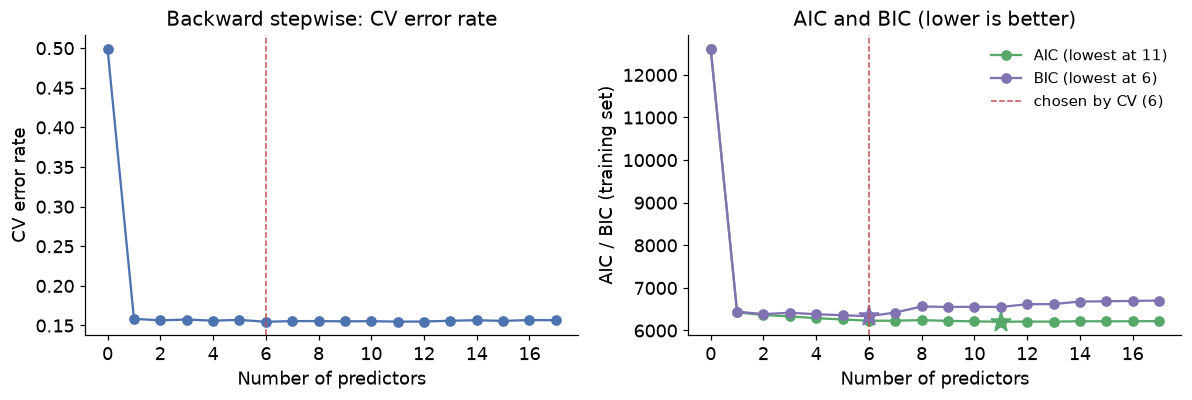

Lowest CV error rate: 6 predictors | lowest AIC: 11 | lowest BIC: 6


,number of predictors,predictors,CV error rate,AIC,BIC
0,0,[],0.499,12610.334,12617.449
1,1,[ProductRelated],0.158,6426.196,6440.427
2,2,"[ProductRelated, PageValues]",0.156,6362.918,6384.265
3,3,"[ProductRelated, PageValues, Month]",0.157,6330.066,6415.451
4,4,"[Administrative_Duration, ProductRelated, Page...",0.156,6288.428,6380.929
5,5,"[Administrative_Duration, ProductRelated, Exit...",0.157,6257.980,6357.597
6,6,"[Administrative, Administrative_Duration, Prod...",0.155,6228.161,6334.893
7,7,"[Administrative, Administrative_Duration, Prod...",0.155,6228.496,6420.614
8,8,"[Administrative, Administrative_Duration, Prod...",0.155,6242.851,6563.047
9,9,"[Administrative, Administrative_Duration, Info...",0.155,6224.309,6551.621


In [12]:
METHOD = METHOD.lower().strip()
assert METHOD in ("forward", "backward", "lasso", "ridge", "elastic net"), "Check the spelling of METHOD."

if METHOD in ("forward", "backward"):
    path = stepwise(METHOD)
    best_size = path.loc[path["CV error rate"] <= path["CV error rate"].min() + 1e-12, "number of predictors"].min()
    best_size = max(best_size, 1)
    chosen = path[path["number of predictors"] == best_size].iloc[0]
    sel_vars = chosen["predictors"]
    sel_cols = cols_for(sel_vars)
    picks = {m: int(path.loc[path[m].idxmin(), "number of predictors"]) for m in ("CV error rate", "AIC", "BIC")}

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    x = path["number of predictors"]
    axes[0].plot(x, path["CV error rate"], "o-", color="#4C72B0")
    axes[0].axvline(best_size, color="#C44E52", ls="--", lw=1)
    axes[0].set(xlabel="Number of predictors", ylabel="CV error rate", title=f"{METHOD.title()} stepwise: CV error rate")
    for m, c in (("AIC", "#55A868"), ("BIC", "#8172B2")):
        axes[1].plot(x, path[m], "o-", color=c, label=f"{m} (lowest at {picks[m]})")
        axes[1].plot(picks[m], path[m].min(), "*", ms=14, color=c)
    axes[1].axvline(best_size, color="#C44E52", ls="--", lw=1, label=f"chosen by CV ({best_size})")
    axes[1].set(xlabel="Number of predictors", ylabel="AIC / BIC (training set)", title="AIC and BIC (lower is better)")
    axes[1].legend(frameon=False, fontsize=10)
    for ax in axes:
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.show()
    print(f"Lowest CV error rate: {picks['CV error rate']} predictors | lowest AIC: {picks['AIC']} | lowest BIC: {picks['BIC']}")
    display(path[["number of predictors", "predictors", "CV error rate", "AIC", "BIC"]])

else:
    mixes = {"lasso": [1.0], "ridge": [0.0], "elastic net": [0.25, 0.5, 0.75]}[METHOD]
    paths = {r: penalized_path(r) for r in mixes}
    path = pd.concat([paths[r][0] for r in mixes], ignore_index=True)
    chosen = choose_lambda(path)
    best_ratio, best_lam = chosen["l1_ratio"], chosen["lambda"]
    path_r, coef_path = paths[best_ratio]
    sel_cols = list(X_COLS) if METHOD == "ridge" else chosen["kept columns"]
    sel_vars = vars_of(sel_cols)

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
    for r in mixes:
        pr = paths[r][0]
        label = {"lasso": "lasso", "ridge": "ridge"}.get(METHOD, f"mix = {r:g} (1 = lasso, 0 = ridge)")
        axes[0].plot(pr["log10(lambda)"], pr["CV error rate"], "o-", ms=4, label=label)
    axes[0].axvline(np.log10(best_lam), color="#C44E52", ls="--", lw=1, label=f"chosen: log₁₀(λ) = {np.log10(best_lam):.2f}")
    axes[0].set(xlabel="log₁₀(λ)  (more penalty →)", ylabel="CV error rate", title=f"{METHOD.title()}: CV error rate")
    axes[0].legend(frameon=False, fontsize=9)
    top = axes[0].secondary_xaxis("top")
    ticks = path_r.iloc[::5]
    top.set_xticks(ticks["log10(lambda)"], ticks["number of predictors"].astype(str))
    top.set_xlabel("Number of predictors kept", fontsize=10)

    # Color the predictors that matter most at the chosen λ (up to 6); the rest are gray
    at_best = coef_path.loc[best_lam].abs().sort_values(ascending=False)
    highlight = [c for c in at_best.index if at_best[c] > 1e-8][:6]
    palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]
    for c in X_COLS:
        if c not in highlight:
            axes[1].plot(np.log10(coef_path.index), coef_path[c], lw=1, color="#C8C8C8")
    for c, col in zip(highlight, palette):
        axes[1].plot(np.log10(coef_path.index), coef_path[c], lw=2, color=col, label=_txt(c))
    axes[1].axvline(np.log10(best_lam), color="#C44E52", ls="--", lw=1)
    axes[1].axhline(0, color="black", lw=0.6)
    axes[1].set(xlabel="log₁₀(λ)  (more penalty →)", ylabel="Coefficient (per SD for quantitative)",
                title="Coefficients shrink as λ grows")
    axes[1].legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0), title="largest at\nchosen λ", title_fontsize=9)
    plt.tight_layout()
    plt.show()
    extra = f", mix = {best_ratio:g}" if METHOD == "elastic net" else ""
    print(f"Chosen λ = {best_lam:.4g} (log₁₀(λ) = {np.log10(best_lam):.2f}{extra}), "
          f"CV error rate = {chosen['CV error rate']:.3f}, {chosen['number of predictors']} predictors kept")

### 3b. The predictors your method kept (Slide: My model selection)

Ridge keeps every predictor, so for ridge this lists the predictors with the largest standardized coefficients (per 1 SD for a quantitative predictor, per category for a qualitative one).

In [13]:
if METHOD == "ridge":
    pipe_r, order_r = make_model(X_COLS, 0.0, best_lam)
    pipe_r.fit(X_train[order_r], y_train)
    b_std = pd.Series(pipe_r.named_steps["logreg"].coef_[0], index=order_r)[X_COLS]
    ranked = b_std.abs().sort_values(ascending=False)
    print("Ridge keeps all predictors. Largest standardized coefficients:")
    display(ranked.rename("|standardized coefficient|").to_frame().head(8))
else:
    dropped = [v for v in pool if v not in sel_vars]
    print(f"Kept ({len(sel_vars)} of {len(pool)}):", ", ".join(sel_vars))
    print(f"Dropped ({len(dropped)}):", ", ".join(dropped) if dropped else "none")
    if METHOD in ("lasso", "elastic net") and len(sel_cols) < len(cols_for(sel_vars)):
        print("Note: for a qualitative predictor, lasso can keep some of its dummy columns and drop others:", sel_cols)

Kept (6 of 17): Administrative, Administrative_Duration, ProductRelated, ExitRates, PageValues, Month
Dropped (11): Informational, Informational_Duration, BounceRates, SpecialDay, OperatingSystems, Browser, Region, TrafficType, VisitorType, Weekend, Revenue


### 3c. About AIC and BIC

Both AIC and BIC reward a good fit and penalize extra predictors; BIC penalizes them more, so it often picks a smaller model. Lower is better for both.

$$\text{AIC} = -2\log L + 2d \qquad \text{BIC} = -2\log L + d\log n$$

Here L is the model's likelihood on the training set, d is the number of coefficients, and n is the number of training rows. AIC and BIC don't apply to a penalized fit, so ridge reports only the CV error rate.

---
# Step 4. Compare and interpret your selected model (you)

Your **selected model** is the model your method chose in Step 3.

- **Stepwise, lasso, or elastic net:** refit an ordinary logistic regression on the training set, using just the predictors your method kept. This gives coefficients in the predictors' original units, with confidence intervals.
- **Ridge:** use the ridge fit itself. Its coefficients are converted back to the predictors' original units.

### 4a. Your selected model's AIC, BIC, and CV error rate (Slide: My model selection)

Your group compares every member's model on these measures in Step 6. Lower is better for all three.

In [14]:
if METHOD == "ridge":
    sel_lam, sel_ratio = best_lam, 0.0
    pipe_sel, order_sel = make_model(X_COLS, 0.0, best_lam)
    pipe_sel.fit(X_train[order_sel], y_train)
    lr = pipe_sel.named_steps["logreg"]
    b_std = pd.Series(lr.coef_[0], index=order_sel)
    mu, sd = X_train[quant].mean(), X_train[quant].std(ddof=0)
    coefs = pd.Series({c: b_std[c] / sd[c] if c in quant else b_std[c] for c in X_COLS})  # back to original units
    intercept = lr.intercept_[0] - sum(b_std[q] * mu[q] / sd[q] for q in quant)
    ci = None
    sel_aic = sel_bic = np.nan
    sel_cv = cv_error(X_COLS, 0.0, best_lam)
    predict_proba = lambda X: pipe_sel.predict_proba(X[order_sel])[:, 1]
else:
    res = fit_unpenalized(sel_cols)
    intercept, coefs = res.params["const"], res.params.drop("const")
    ci = np.exp(res.conf_int().drop("const"))
    sel_aic, sel_bic = aic_bic(res)
    sel_cv = cv_error(sel_cols)
    predict_proba = lambda X: np.asarray(res.predict(sm.add_constant(X[sel_cols], has_constant="add")))

my_selection = pd.Series({"method": METHOD, "number of predictors": len(sel_vars),
                          "CV error rate": round(sel_cv, 3),
                          "AIC": "n/a (ridge)" if METHOD == "ridge" else round(sel_aic, 1),
                          "BIC": "n/a (ridge)" if METHOD == "ridge" else round(sel_bic, 1)}, name=MY_NAME)
my_selection.to_frame()

,Matthew Burger
method,backward
number of predictors,6
CV error rate,0.155
AIC,6228.2
BIC,6334.9


### 4b. Write your selected model in math (Slide: My selected model)

Your slide must show your model in log-odds form, with p defined, and the fitted equation with your estimates. This cell writes both. If your model has many predictors, it shows the two with the largest standardized coefficients, then "+ …".

- Each dummy variable gets its own β, and the baseline category has none.

In [15]:
show_equations(intercept, coefs)

**Your model** (p = P(EngagedUser = 1), the probability of spent more than 516.479 seconds (8.61 minutes) browsing product pages):

<IPython.core.display.Math object>

**Fitted equation:**

<IPython.core.display.Math object>

Plain text to paste into your slide:
  log(p / (1 − p)) = β₀ + β₁·ProductRelated + β₂·Month_Nov + …
  log(p / (1 − p)) = -3.13 + 0.174·ProductRelated + 0.491·Month_Nov + …
  where p = P(EngagedUser = 1)

(Your model has 14 terms; the slide shows the two with the largest standardized coefficients, then '+ …'.)


### 4c. Your coefficients as odds ratios (Slide: My selected model)

An **odds ratio** is e^β: the number the odds of the outcome are multiplied by, holding the other predictors fixed.

- **Quantitative predictor:** for each one-unit increase. An odds ratio of 1.25 means 25% higher odds per unit; 0.90 means 10% lower odds.
- **Qualitative predictor:** the odds for that category compared with the baseline category.
- An odds ratio above 1 raises the odds of the outcome; below 1 lowers them; exactly 1 means no change.
- If one unit is tiny (one career hit, one dollar), interpret a bigger, meaningful change instead: for 100 units, the odds are multiplied by e^(100β), that is, the odds ratio to the power 100.

In [16]:
odds = pd.DataFrame({"coefficient (log-odds)": coefs, "odds ratio": np.exp(coefs),
                     "% change in odds": 100 * (np.exp(coefs) - 1)})
if ci is not None:
    odds["OR 95% CI low"], odds["OR 95% CI high"] = ci[0], ci[1]
odds["per"] = ["1 unit" if c in quant else f"vs. {BASELINE[VAR_OF[c]]} (baseline)" for c in odds.index]
used_qual = sorted({VAR_OF[c] for c in coefs.index if c not in quant})
for v in used_qual:
    print(f"Baseline category of {v}: {BASELINE[v]}")
if METHOD == "ridge":
    print("Ridge: the coefficients are shrunk toward 0, so these odds ratios are pulled toward 1.")
odds.reindex(standardized_size(coefs).sort_values(ascending=False).index)

Baseline category of Month: Aug


,coefficient (log-odds),odds ratio,% change in odds,OR 95% CI low,OR 95% CI high,per
ProductRelated,0.174,1.190,19.011,1.180e+00,1.200,1 unit
Month[Nov],0.491,1.635,63.451,1.132e+00,2.361,vs. Aug (baseline)
Month[June],-0.444,0.641,-35.863,3.617e-01,1.137,vs. Aug (baseline)
Month[Dec],0.382,1.465,46.456,1.003e+00,2.138,vs. Aug (baseline)
Administrative_Duration,0.002,1.002,0.243,1.002e+00,1.003,1 unit
Month[Mar],0.352,1.422,42.224,9.801e-01,2.064,vs. Aug (baseline)
ExitRates,-6.668,0.001,-99.873,1.471e-04,0.011,1 unit
Administrative,-0.094,0.911,-8.941,8.811e-01,0.941,1 unit
Month[May],0.236,1.266,26.607,8.824e-01,1.816,vs. Aug (baseline)
PageValues,0.012,1.012,1.173,1.008e+00,1.015,1 unit


### 4d. ✏️ Interpret at least two coefficients (Slide: My selected model)

Interpret **at least two** coefficients, either quantitative or qualitative, as odds ratios, holding the other predictors fixed. Fill in the sentences with your numbers.

✏️ **Quantitative coefficient:** Holding the other predictors fixed, each one-unit increase in ProductRelated (product-related pages visited) multiplies the odds of an engaged user by 1.190 (a 19.0% increase in the odds).

✏️ **Qualitative coefficient:** Holding the other predictors fixed, sessions in the November category have 1.635 times the odds of an engaged user with the baseline category, August.

✏️ **Your second coefficient:** Holding the other predictors fixed, each additional administrative page visited multiplies the odds of an engaged user by 0.911 (an 8.9% decrease in the odds).

**Ridge:** say that your odds ratios are pulled toward 1, because the penalty shrinks the coefficients toward 0.

### 4e. Optional: a bootstrap 95% confidence interval for one odds ratio

The bootstrap resamples the training rows with replacement, refits your selected model each time, and takes the middle 95% of the odds ratios. Set `BOOT_TERM` to one of the column names in the odds-ratio table.

In [17]:
# ✏️ EDIT (optional): which odds ratio, and whether to run it
RUN_BOOTSTRAP = True
BOOT_TERM = standardized_size(coefs).idxmax()   # or a column name, e.g. "Years"
B = 300                                          # number of bootstrap samples

if RUN_BOOTSTRAP:
    rng = np.random.default_rng(SEED)
    boot = []
    for _ in range(B):
        idx = rng.integers(0, len(train), len(train))
        Xb, yb = X_train.iloc[idx], y_train[idx]
        if METHOD == "ridge":
            pipe_b, order_b = make_model(X_COLS, 0.0, best_lam)
            pipe_b.fit(Xb[order_b], yb)
            bb = pd.Series(pipe_b.named_steps["logreg"].coef_[0], index=order_b)[BOOT_TERM]
            bb = bb / Xb[BOOT_TERM].std(ddof=0) if BOOT_TERM in quant else bb
        else:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                bb = sm.Logit(yb, sm.add_constant(Xb[sel_cols], has_constant="add")).fit(disp=0, maxiter=500).params[BOOT_TERM]
        boot.append(np.exp(bb))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"Odds ratio for {BOOT_TERM}: {np.exp(coefs[BOOT_TERM]):.3f}, bootstrap 95% CI [{lo:.3f}, {hi:.3f}] from {B} samples")

Odds ratio for ProductRelated: 1.190, bootstrap 95% CI [1.182, 1.201] from 300 samples


---
# Step 5. Test your final model (you)

Now, and only now, use the test set, **once**. Your selected model gives each test case a predicted probability of being 1; a case is classified as 1 if that probability is above 0.5.

- **Test accuracy:** the proportion of test cases classified correctly. Higher is better.
- **Confusion matrix:** the counts of true positives, false positives, true negatives, and false negatives.
- **Precision:** the proportion of predicted 1s that are truly 1.
- **Recall:** the proportion of true 1s predicted as 1.
- **Baseline:** the accuracy of always predicting the most common class in the training set. Your model should beat it.

In [18]:
prob_test = predict_proba(X_test)
pred_test = (prob_test > 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
majority = int(round(y_train.mean()))
test_metrics = pd.Series({
    "test accuracy": accuracy_score(y_test, pred_test),
    "baseline accuracy": float(np.mean(y_test == majority)),
    "precision": precision_score(y_test, pred_test, zero_division=0),
    "recall": recall_score(y_test, pred_test, zero_division=0),
    "AUC": roc_auc_score(y_test, prob_test),
}, name=MY_NAME)
print(f"Baseline: always predict {majority} ({CLASS_1 if majority else CLASS_0})")
test_metrics.round(3).to_frame()

Baseline: always predict 1 (spent more than 516.479 seconds (8.61 minutes) browsing product pages)


,Matthew Burger
test accuracy,0.854
baseline accuracy,0.497
precision,0.867
recall,0.833
AUC,0.927


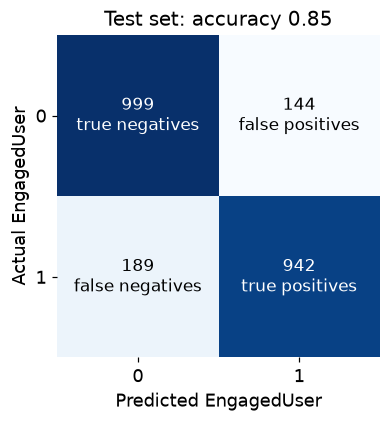

In [19]:
# Confusion matrix on the test set
fig, ax = plt.subplots(figsize=(4.8, 4))
cm = np.array([[tn, fp], [fn, tp]])
names = np.array([["true negatives", "false positives"], ["false negatives", "true positives"]])
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{names[i, j]}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
ax.set_xticks([0, 1], ["0", "1"])
ax.set_yticks([0, 1], ["0", "1"])
ax.set(xlabel=f"Predicted {Y_NAME}", ylabel=f"Actual {Y_NAME}",
       title=f"Test set: accuracy {test_metrics['test accuracy']:.2f}")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

### 5a. The ROC curve and AUC (Slide: My selected model)

The ROC curve shows the true positive rate (recall) against the false positive rate (the proportion of true 0s predicted as 1) as the probability cutoff moves from 0 to 1. The **AUC** (area under the curve) is the probability that your model gives a randomly chosen 1 a higher predicted probability than a randomly chosen 0: 0.5 is no better than chance, and 1 is perfect.

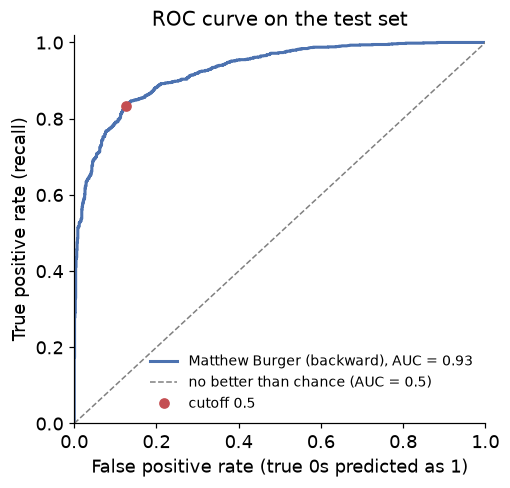

In [20]:
fpr, tpr, _ = roc_curve(y_test, prob_test)
cut = (fp / max(fp + tn, 1), tp / max(tp + fn, 1))   # where the 0.5 cutoff sits on the curve
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot(fpr, tpr, color="#4C72B0", lw=2, label=f"{MY_NAME} ({METHOD}), AUC = {test_metrics['AUC']:.2f}")
ax.plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="no better than chance (AUC = 0.5)")
ax.plot(*cut, "o", color="#C44E52", label="cutoff 0.5")
ax.set(xlabel="False positive rate (true 0s predicted as 1)", ylabel="True positive rate (recall)",
       title="ROC curve on the test set", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

✏️ **Interpret your AUC in one sentence** for your slide:

An AUC of .93 means that, for a randomly chosen engaged sessions and unengaged session, our model gives the engaged user the higher probability 93% of the time.

In [21]:
# Your row for the group's comparison table: send this to the member doing Step 6
aic_txt = "None" if METHOD == "ridge" else f"{sel_aic:.1f}"
bic_txt = "None" if METHOD == "ridge" else f"{sel_bic:.1f}"
print(f'"{MY_NAME}": ("{METHOD}", "{", ".join(sel_vars)}", {sel_cv:.3f}, {aic_txt}, {bic_txt}, '
      f'{test_metrics["test accuracy"]:.3f}, {test_metrics["AUC"]:.3f}, {test_metrics["precision"]:.3f}, '
      f'{test_metrics["recall"]:.3f}, {tp}, {fp}, {tn}, {fn}),')
print(f"Test set fingerprint: {fingerprint} | fold fingerprint: {fold_print}")

"Matthew Burger": ("backward", "Administrative, Administrative_Duration, ProductRelated, ExitRates, PageValues, Month", 0.155, 6228.2, 6334.9, 0.854, 0.927, 0.867, 0.833, 942, 144, 999, 189),
Test set fingerprint: 39c7f0e1 | fold fingerprint: 8084f47f


---
# Step 6. Compare your models as a group (one member)

One member collects everyone's row from the end of Step 5, pastes them below, and runs these cells. The table goes on your **Model comparison** slide. Check that everyone's fingerprints matched.

In [22]:
# ✏️ EDIT: replace these example rows with each member's row from Step 5
results = {
    # name: (method, predictors kept, CV error rate, AIC, BIC, test accuracy, AUC, precision, recall, TP, FP, TN, FN)
    "Nicholas Chan": ("elastic net", "Administrative, Administrative_Duration, Informational, Informational_Duration, ProductRelated, BounceRates, ExitRates, PageValues, SpecialDay, Month, OperatingSystems, Browser, Region, TrafficType, VisitorType, Revenue", 0.155, 6170.5, 6433.8, 0.849, 0.928, 0.864, 0.827, 935, 147, 996, 196),
    "Matthew Burger": ("backward", "Administrative, Administrative_Duration, ProductRelated, ExitRates, PageValues, Month", 0.155, 6228.2, 6334.9, 0.854, 0.927, 0.867, 0.833, 942, 144, 999, 189),
    "Jacob Doan": ("lasso", "Administrative, Administrative_Duration, Informational, Informational_Duration, ProductRelated, BounceRates, ExitRates, PageValues, SpecialDay, Month, Browser, Region, TrafficType, VisitorType, Revenue", 0.155, 6161.2, 6353.4, 0.852, 0.929, 0.869, 0.828, 936, 141, 1002, 195),
}

cols = ["method", "predictors kept", "CV error rate", "AIC", "BIC", "test accuracy", "AUC",
        "precision", "recall", "TP", "FP", "TN", "FN"]
comparison = pd.DataFrame(results, index=cols).T
comparison.insert(1, "number of predictors", comparison["predictors kept"].str.split(", ").str.len())
baseline_acc = float(np.mean(y_test == int(round(y_train.mean()))))
comparison.loc["Baseline (most common class)"] = ["none", 0, "", np.nan, np.nan, np.nan, baseline_acc, 0.5,
                                                  np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]
comparison.drop(columns="predictors kept")

,method,number of predictors,CV error rate,AIC,BIC,test accuracy,AUC,precision,recall,TP,FP,TN,FN
Nicholas Chan,elastic net,16,0.155,6170.5,6433.8,0.849,0.928,0.864,0.827,935,147,996,196
Matthew Burger,backward,6,0.155,6228.2,6334.9,0.854,0.927,0.867,0.833,942,144,999,189
Jacob Doan,lasso,15,0.155,6161.2,6353.4,0.852,0.929,0.869,0.828,936,141,1002,195
Baseline (most common class),none,0,NaN,NaN,NaN,0.497,0.5,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
# Which predictors did each method keep?
members = [m for m in comparison.index if m != "Baseline (most common class)"]
kept = pd.DataFrame({m: {v: "✓" if v in comparison.loc[m, "predictors kept"].split(", ") else "" for v in pool}
                     for m in members})
kept["kept by"] = (kept == "✓").sum(axis=1)
kept.sort_values("kept by", ascending=False)

,Nicholas Chan,Matthew Burger,Jacob Doan,kept by
Administrative,✓,✓,✓,3
Administrative_Duration,✓,✓,✓,3
ProductRelated,✓,✓,✓,3
PageValues,✓,✓,✓,3
ExitRates,✓,✓,✓,3
Month,✓,✓,✓,3
Informational_Duration,✓,,✓,2
BounceRates,✓,,✓,2
Informational,✓,,✓,2
SpecialDay,✓,,✓,2


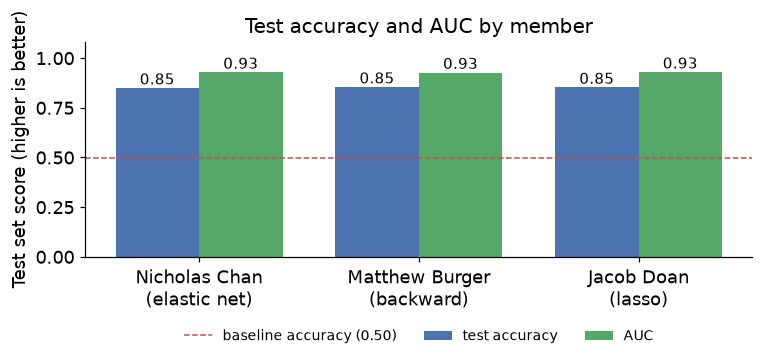

In [24]:
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(members))
w = 0.38
acc = comparison.loc[members, "test accuracy"].astype(float)
auc = comparison.loc[members, "AUC"].astype(float)
ax.bar(x - w / 2, acc, w, label="test accuracy", color="#4C72B0")
ax.bar(x + w / 2, auc, w, label="AUC", color="#55A868")
ax.axhline(baseline_acc, color="#C44E52", ls="--", lw=1, label=f"baseline accuracy ({baseline_acc:.2f})")
for i in range(len(members)):
    ax.text(i - w / 2, acc.iloc[i], f"{acc.iloc[i]:.2f}", ha="center", va="bottom", fontsize=10)
    ax.text(i + w / 2, auc.iloc[i], f"{auc.iloc[i]:.2f}", ha="center", va="bottom", fontsize=10)
ax.set_xticks(x, [f"{m}\n({comparison.loc[m, 'method']})" for m in members])
ax.set(ylim=(0, 1.08), ylabel="Test set score (higher is better)", title="Test accuracy and AUC by member")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3)
plt.tight_layout()
plt.show()

✏️ **For your Model comparison slide** (one or two sentences each):

- **Which model predicts best on the test set, and why?**
- **Did the methods agree on which predictors matter?**
- **Did AIC, BIC, and CV point to the same models?**

---
# Before you submit

**This notebook**

- [ ] Steps 1 and 2 match your teammates', and both fingerprints match theirs
- [ ] Your method is different from every teammate's
- [ ] Step 4d interprets at least two coefficients as odds ratios, naming the baseline for any qualitative predictor
- [ ] Step 5 has your test accuracy, confusion matrix, precision, recall, and ROC curve with the AUC interpreted
- [ ] **Runtime → Restart and run all** finishes without errors
- [ ] The file is named with your name and saved in your group's Drive folder

**Your slides**

- [ ] My model selection slide: your method, the CV error plot with your chosen value marked (stepwise: AIC and BIC too), the predictors kept, and your selected model's AIC, BIC, and CV error rate
- [ ] My selected model slide: your model in math with p defined, the fitted equation, two odds-ratio interpretations, test accuracy, confusion matrix, precision, recall, baseline accuracy, and the ROC curve with its AUC interpreted
- [ ] Every figure has labeled axes